# Preference-aware recommendations from a Pareto approximation

* Contributors: [M-Colley](https://github.com/M-Colley)
* Last updated: October 21, 2026
* Executed with BoTorch 0.18.1 and PyTorch 2.14.1+cpu; the setup cell reports the versions used on a rerun.

A multiobjective optimizer returns alternatives. A separate decision is needed when we must recommend one tested design. This notebook implements that final, **a posteriori** step using the published two-stage rule of [Schmitt, Hoffmann, Rodemann, and Adamy (2022)](https://doi.org/10.3390/inventions7030046): identify a knee region, then select within it using a preference hyperplane.

We compare this rule with an ordinary normalized weighted cost and the closest-to-ideal recommendation. The example also shows an important tradeoff: a knee restriction can exclude an extreme design that is entirely legitimate under the supplied preferences. The method expresses an additional preference for compromise; it does not discover the decision maker's true utility.


In [1]:
import matplotlib.pyplot as plt
import torch

import botorch
from botorch.utils.multi_objective.pareto import is_non_dominated
from botorch_community.utils.multi_objective.decision_making import (
    knee_region,
    select_preferred,
)

torch.set_default_dtype(torch.float64)
print(f"BoTorch {botorch.__version__}; PyTorch {torch.__version__}")


C:\Users\Mark\Desktop\openbo\.venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


BoTorch 0.18.1; PyTorch 2.14.1+cpu


## Recommend from measured outcomes

Suppose the rows below are exact outcomes of nine tested designs, with two costs to minimize. The last design is dominated. We store rewards `train_Y = -observed_costs`, so the recommendation functions use BoTorch's usual maximization convention. With noisy measurements, deciding what counts as a credible Pareto alternative requires additional uncertainty analysis.

The selector filters dominated rows and keeps the first duplicate before computing objective ranges. Returned indices always refer to the original rows, making it straightforward to retrieve a design from `train_X`.


In [2]:
train_X = torch.linspace(0, 1, 9).unsqueeze(-1)
observed_costs = torch.tensor(
    [
        [0.00, 1.00],
        [0.04, 0.78],
        [0.10, 0.60],
        [0.20, 0.40],
        [0.35, 0.27],
        [0.55, 0.18],
        [0.75, 0.09],
        [1.00, 0.00],
        [0.60, 0.65],  # Dominated by multiple tested designs.
    ]
)
train_Y = -observed_costs
pareto = is_non_dominated(train_Y)
preferences = torch.tensor([0.95, 0.05])
alpha = 0.8

in_knee = knee_region(train_Y, alpha=alpha)
recommended_index = select_preferred(train_Y, preferences, alpha=alpha)
recommended_X = train_X[recommended_index]

assert not pareto[-1]
assert recommended_index.item() == 3
print("Original row:", recommended_index.item())
print("Recommended design:", recommended_X.tolist())
print("Observed costs:", observed_costs[recommended_index].tolist())


Original row: 3
Recommended design: [0.375]
Observed costs: [0.2, 0.4]


## The published geometry

Let $z^i$ be normalized **minimization costs**, with the componentwise best and worst Pareto outcomes mapped to zero and one. This orientation also applies when the input contains maximization rewards. The source calls the componentwise best vector the Utopia point; no strict improvement offset is introduced here.

Equations (9)–(11) of Schmitt et al. choose

$$q=\operatorname*{arg\,max}_i\|z^i\|_2,\qquad
\delta_i=\frac{\mathbf{1}^{\mathsf T}(z^q-z^i)}{\sqrt m},\qquad
K_\alpha=\lbrace i:\delta_i\geq\alpha\max_j\delta_j\rbrace,\quad \alpha\in[0,1].$$

The preference-plane condition in Equation (13) is equivalent to

$$b=\operatorname*{arg\,min}_{i\in K_\alpha}p^{\mathsf T}z^i.$$

Larger nonnegative preference coefficients prioritize reducing their corresponding normalized costs. Scaling every coefficient by the same positive constant has no effect. `alpha` controls the allowed knee region, not a confidence level or a probability of human error. The discrete choice is not differentiable. Exact score ties select the earliest retained input row.


In [3]:
# Normalize all three comparison methods using the same Pareto ranges.
front_costs = observed_costs[pareto]
ideal = front_costs.amin(dim=0)
nadir = front_costs.amax(dim=0)
normalized_costs = (observed_costs - ideal) / (nadir - ideal)

weighted_scores = (normalized_costs * preferences).sum(dim=-1)
ideal_distances = torch.linalg.vector_norm(normalized_costs, dim=-1)
weighted_index = weighted_scores.masked_fill(~pareto, torch.inf).argmin()
ideal_index = ideal_distances.masked_fill(~pareto, torch.inf).argmin()

methods = {
    "Normalized weighted cost": weighted_index,
    "Closest to ideal": ideal_index,
    "Knee + preference plane": recommended_index,
}
for name, index in methods.items():
    print(
        f"{name:26s} row={index.item()}  "
        f"costs={observed_costs[index].tolist()}  "
        f"weighted cost={weighted_scores[index].item():.4f}"
    )

assert weighted_index.item() == 0
assert ideal_index.item() == 4
assert not in_knee[weighted_index]  # A legitimate preference-optimal extreme.
assert in_knee[recommended_index]


Normalized weighted cost   row=0  costs=[0.0, 1.0]  weighted cost=0.0500
Closest to ideal           row=4  costs=[0.35, 0.27]  weighted cost=0.3460
Knee + preference plane    row=3  costs=[0.2, 0.4]  weighted cost=0.2100


The ordinary weighted rule chooses row 0, which best reflects the stated linear utility over these normalized outcomes. The knee rule excludes it and chooses row 3. Closest-to-ideal ignores the supplied preference vector and chooses row 4. These are different decision policies, rather than an ordering from worse to better.

The left panel shows the distance plane and the threshold that defines the knee region. The right panel changes the first preference coefficient while holding the same tested outcomes fixed. A finite set produces stepwise recommendations. The knee restriction limits how far they can move toward either extreme.


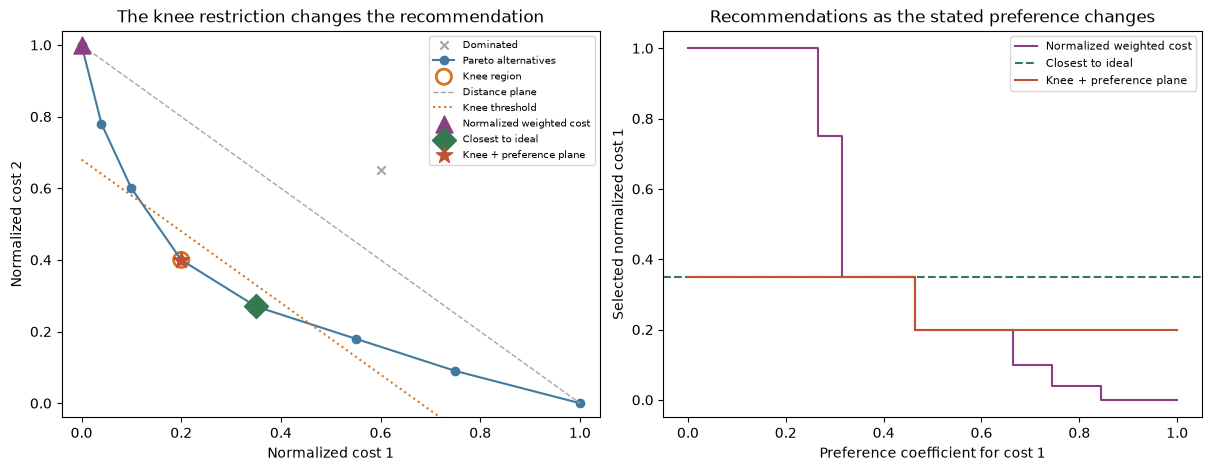

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)
ax = axes[0]
z = normalized_costs.detach().cpu()
ax.scatter(z[~pareto, 0], z[~pareto, 1], color="0.65", marker="x", label="Dominated")
ax.plot(z[pareto, 0], z[pareto, 1], "o-", color="#427A9F", label="Pareto alternatives")
ax.scatter(z[in_knee, 0], z[in_knee, 1], s=120, facecolors="none",
           edgecolors="#D47724", linewidths=2, label="Knee region")

front_z = normalized_costs[pareto]
q = torch.linalg.vector_norm(front_z, dim=-1).argmax()
plane_sum = front_z[q].sum().item()
delta_max = plane_sum - front_z.sum(dim=-1).min().item()
xx = torch.linspace(0, 1, 101)
ax.plot(xx, plane_sum - xx, "--", color="0.65", linewidth=1,
        label="Distance plane")
ax.plot(xx, plane_sum - alpha * delta_max - xx, ":", color="#D47724",
        linewidth=1.5, label="Knee threshold")

markers = ["^", "D", "*"]
colors = ["#8A3F82", "#367850", "#C54F35"]
for (name, index), marker, color in zip(methods.items(), markers, colors):
    ax.scatter(z[index, 0], z[index, 1], s=150, marker=marker,
               color=color, zorder=5, label=name)
ax.set(xlim=(-0.04, 1.04), ylim=(-0.04, 1.04),
       xlabel="Normalized cost 1", ylabel="Normalized cost 2",
       title="The knee restriction changes the recommendation")
ax.legend(fontsize=7.5, loc="upper right")

first_preferences = torch.linspace(0, 1, 101)
preference_grid = torch.stack([first_preferences, 1 - first_preferences], dim=-1)
catalogs = train_Y.expand(len(preference_grid), -1, -1)
knee_indices = select_preferred(catalogs, preference_grid, alpha=alpha)
full_scores = (normalized_costs.unsqueeze(0) * preference_grid.unsqueeze(1)).sum(-1)
full_indices = full_scores.masked_fill(~pareto.unsqueeze(0), torch.inf).argmin(-1)

ax = axes[1]
ax.step(first_preferences, normalized_costs[full_indices, 0], where="mid",
        color=colors[0], label="Normalized weighted cost")
ax.axhline(normalized_costs[ideal_index, 0], color=colors[1], linestyle="--",
           label="Closest to ideal")
ax.step(first_preferences, normalized_costs[knee_indices, 0], where="mid",
        color=colors[2], label="Knee + preference plane")
ax.set(xlabel="Preference coefficient for cost 1", ylabel="Selected normalized cost 1",
       title="Recommendations as the stated preference changes")
ax.legend(fontsize=8)
plt.show()


## Signed distances: `alpha=0` has a subtle boundary

Equation (10) uses a **signed** distance, not its absolute value. The largest Euclidean norm need not identify the largest sum of normalized costs. A Pareto alternative can therefore lie on the negative side of the distance plane and have $\delta_i<0$.

The three-objective example below is already normalized and every row is nondominated. Row 1 has sum 2.4 but norm below $\sqrt{2}$. The source distance plane passes through the first maximum-norm row, whose sum is 2. Consequently `alpha=0` still excludes row 1. Replacing the norm-based anchor with a largest-sum anchor, or taking absolute distances, would implement a different method.


In [5]:
nonconvex_costs = torch.tensor(
    [[1.0, 1.0, 0.0], [0.8, 0.8, 0.8], [0.0, 1.0, 1.0], [1.0, 0.0, 1.0]]
)
assert is_non_dominated(-nonconvex_costs).all()
q3 = torch.linalg.vector_norm(nonconvex_costs, dim=-1).argmax()
signed_distances = (
    nonconvex_costs[q3].sum() - nonconvex_costs.sum(dim=-1)
) / (3 ** 0.5)
mask_at_zero = knee_region(nonconvex_costs, alpha=0, maximize=False)
print("Signed distances:", signed_distances.tolist())
print("Knee mask at alpha=0:", mask_at_zero.tolist())
assert mask_at_zero.tolist() == [True, False, True, True]


Signed distances: [0.0, -0.23094010767585052, 0.0, 0.0]
Knee mask at alpha=0: [True, False, True, True]


## Batched recommendations

Outcome tensors have shape `(..., n, m)` and preference tensors have shape `(..., m)`. Preferences broadcast over the outcome batch dimensions. Here the same catalog is evaluated under three preference vectors; this also covers independently supplied catalogs of the same shape.


In [6]:
preference_batch = torch.tensor([[0.95, 0.05], [0.50, 0.50], [0.05, 0.95]])
outcome_batch = train_Y.expand(3, -1, -1)
batch_indices = select_preferred(outcome_batch, preference_batch, alpha=alpha)
batch_masks = knee_region(outcome_batch, alpha=alpha)
assert batch_indices.shape == torch.Size([3])
assert batch_masks.shape == torch.Size([3, len(train_Y)])
print("Original rows:", batch_indices.tolist())
print("Recommended costs:", observed_costs[batch_indices].tolist())


Original rows: [3, 3, 4]
Recommended costs: [[0.2, 0.4], [0.2, 0.4], [0.35, 0.27]]


## Where this fits in a Bayesian optimization workflow

After a multiobjective BO run, pass the measured outcome catalog and a stated preference vector to `select_preferred`, then use its original-row index to retrieve the tested design. The preference vector can change while the measurements remain fixed; no surrogate retraining is needed to rerank that catalog.

The same tensor interface can consume `model.posterior(X_catalog).mean` for a finite candidate catalog. Such a recommendation concerns **predicted mean outcomes**, rather than measured performance or a probability of Pareto optimality. Keep posterior uncertainty and any feasibility requirements in the surrounding decision process. The selector itself does not learn preferences, model human feedback errors, perform experimental acquisition, or provide closed-loop stability guarantees.

Sample-based normalization depends on which alternatives have been found. New extreme observations can change both the knee region and the meaning of a preference coefficient. Use domain knowledge to decide whether those adaptive ranges express the intended comparison. Constant observed columns contribute no discrimination; this does not prove the objective is constant over unobserved designs.

## Optional front generation: FPBI is a separate component

Section 4 of Schmitt et al. also introduces **focus point boundary intersection (FPBI)**, a continuous constrained method for approximating a front. That is a separate front-generation algorithm. This contribution includes only the two-stage finite-outcome selector; it can receive outcomes generated by BO, FPBI, another optimizer, or measured alternatives.

A fuller FPBI solver can be developed and maintained in an external package such as OpenBO, then pass its outcome tensor to this selector. No external FPBI package or unpublished local API is required to execute this notebook. In particular, front-generation performance and MPC stability are outside the claims demonstrated here.

## Reference

Thomas Schmitt, Matthias Hoffmann, Tobias Rodemann, and Jürgen Adamy. 2022. [Incorporating Human Preferences in Decision Making for Dynamic Multi-Objective Optimization in Model Predictive Control](https://doi.org/10.3390/inventions7030046). *Inventions* 7(3), 46. The selector follows Equations (8)–(13); this notebook demonstrates its use with BoTorch outcome tensors.
